In [1]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt

In [2]:
RAW = "data/raw"
HELD_OUT = ["airplane", "axe"]
rng = np.random.default_rng(42)


In [3]:
gal_X = []
gal_y = []
qry_X = []
qry_y = []
held_X = []
held_y = []


for path in sorted(glob.glob(os.path.join(RAW, "*.npy"))):
    name = os.path.basename(path).replace("full_numpy_bitmap_", "").replace(".npy", "")
    data = np.load(path, mmap_mode="r")          # reads from disk only when indexed
    if name in HELD_OUT:
        idx = np.sort(rng.choice(len(data), 50, replace=False))
        held_X.append(data[idx]);  held_y += [name] * 50
    else:
        idx = rng.choice(len(data), 500, replace=False)
        g, q = np.sort(idx[:450]), np.sort(idx[450:])
        gal_X.append(data[g]);  gal_y += [name] * 450
        qry_X.append(data[q]);  qry_y += [name] * 50
    print(name, len(data))


airplane 151623
apple 144722
axe 124122
banana 307936
bear 134762
bird 133572
bowtie 130283
butterfly 117999
cake 124905
car 182764
donut 140751
hat 222610
house 135420
mouse 178826
tree 144721


In [4]:
gallery_images = np.concatenate(gal_X);  gallery_labels = np.array(gal_y)
query_images   = np.concatenate(qry_X);  query_labels   = np.array(qry_y)
heldout_images = np.concatenate(held_X); heldout_labels = np.array(held_y)

In [5]:
np.savez("data/subset.npz",
         gallery_images=gallery_images, gallery_labels=gallery_labels,
         query_images=query_images, query_labels=query_labels,
         heldout_images=heldout_images, heldout_labels=heldout_labels)

In [6]:
print(gallery_images.shape, query_images.shape, heldout_images.shape)
print(gallery_images.dtype, gallery_images.min(), gallery_images.max())
print(np.unique(gallery_labels, return_counts=True))

(5850, 784) (650, 784) (100, 784)
uint8 0 255
(array(['apple', 'banana', 'bear', 'bird', 'bowtie', 'butterfly', 'cake',
       'car', 'donut', 'hat', 'house', 'mouse', 'tree'], dtype='<U9'), array([450, 450, 450, 450, 450, 450, 450, 450, 450, 450, 450, 450, 450]))


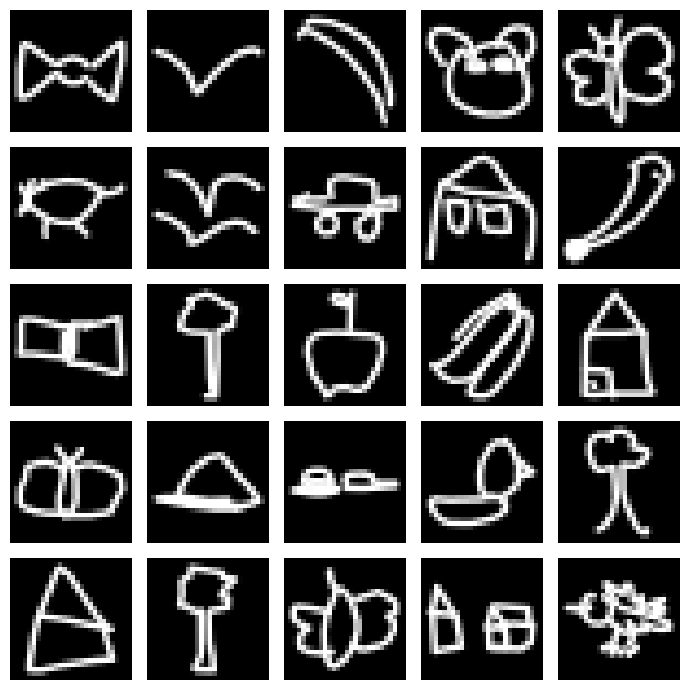

In [7]:
pick = rng.choice(len(gallery_images), 25, replace=False)
plt.figure(figsize=(7, 7))
for i, j in enumerate(pick):
    plt.subplot(5, 5, i + 1)
    plt.imshow(gallery_images[j].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from keras.applications import MobileNetV2
from keras.applications.mobilenet_v2 import preprocess_input

backbone = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")
backbone.trainable = False



C:\Users\Ayman {Ed}\AppData\Local\Temp\ipykernel_23424\1792817036.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")


In [ ]:
def to_model_input(images_28, invert=False):
    x = np.asarray(images_28, dtype="float32").reshape(-1, 28, 28, 1)
    if invert:
        x = 255.0 - x
    x = tf.image.resize(x, (224, 224)).numpy()
    x = np.repeat(x, 3, axis=-1)
    return preprocess_input(x)

In [ ]:
def embed(model, images_28, invert=False, batch_size=64):
    out = []
    for i in range(0, len(images_28), batch_size):
        out.append(model.predict(to_model_input(images_28[i:i+batch_size], invert), verbose=0))
    emb = np.concatenate(out)
    return emb / np.linalg.norm(emb, axis=1, keepdims=True)

In [11]:
gallery_emb = embed(backbone, gallery_images)

np.save("index/embeddings.npy", gallery_emb)
np.save("index/gallery_images.npy", gallery_images)
np.save("index/gallery_labels.npy", gallery_labels)

print(gallery_emb.shape)
print(np.linalg.norm(gallery_emb, axis=1)[:5])

(5850, 1280)
[0.99999994 1.         0.99999994 0.99999994 0.99999994]


In [ ]:
from PIL import Image, ImageOps

def preprocess_query(image):
    img = Image.alpha_composite(Image.new("RGBA", image.size, "white"), image.convert("RGBA")).convert("L")
    img = ImageOps.invert(img)
    box = img.getbbox()
    if box is None:
        return None
    img = ImageOps.pad(img.crop(box), (20, 20))
    return np.array(ImageOps.expand(img, border=4, fill=0))

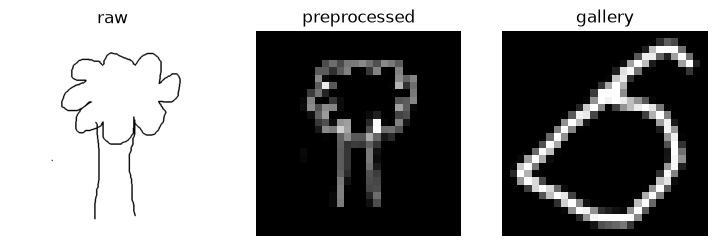

In [15]:
raw = Image.open("test_paint.png")
out = preprocess_query(raw)

plt.figure(figsize=(9, 3))
plt.subplot(1, 3, 1); plt.imshow(raw);                                        plt.title("raw");          plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(out, cmap="gray");                           plt.title("preprocessed"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(gallery_images[0].reshape(28, 28), cmap="gray"); plt.title("gallery");  plt.axis("off")
plt.show()

In [ ]:
def search(query_vector, embeddings, k):
    scores = embeddings @ query_vector
    idx = np.argsort(scores)[::-1][:k]
    return idx, scores[idx]

def precision_table(q_emb, g_emb):
    order = np.argsort(-(q_emb @ g_emb.T), axis=1)
    out = []
    for k in (5, 25):
        top = gallery_labels[order[:, :k]]
        out.append((top == query_labels[:, None]).mean())
    return out

# your model
query_emb = embed(backbone, query_images)
print("Your model:", precision_table(query_emb, gallery_emb))

# raw-pixel baseline
g_raw = gallery_images.astype("float32");  g_raw /= np.linalg.norm(g_raw, axis=1, keepdims=True)
q_raw = query_images.astype("float32");    q_raw /= np.linalg.norm(q_raw, axis=1, keepdims=True)
print("Raw pixels:", precision_table(q_raw, g_raw))

Your model: [np.float64(0.788923076923077), np.float64(0.7318769230769231)]
Raw pixels: [np.float64(0.6332307692307693), np.float64(0.5348307692307692)]


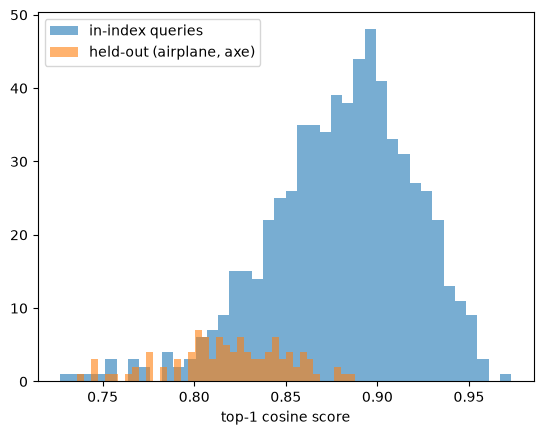

threshold: 0.86
in-index queries wrongly rejected: 181 of 650
held-out doodles wrongly accepted: 8 of 100


In [ ]:
import json


in_top1   = (query_emb @ gallery_emb.T).max(axis=1)
held_emb  = embed(backbone, heldout_images)
held_top1 = (held_emb @ gallery_emb.T).max(axis=1)

plt.hist(in_top1,   bins=40, alpha=0.6, label="in-index queries")
plt.hist(held_top1, bins=40, alpha=0.6, label="held-out (airplane, axe)")
plt.xlabel("top-1 cosine score"); plt.legend(); plt.show()


thresholds = np.linspace(0.3, 0.95, 66)
wrong_reject = np.array([(in_top1   <  t).mean() for t in thresholds])  
wrong_accept = np.array([(held_top1 >= t).mean() for t in thresholds])  
best = thresholds[np.argmin(wrong_reject + wrong_accept)]

print("threshold:", round(best, 3))
print("in-index queries wrongly rejected:", (in_top1   <  best).sum(), "of", len(in_top1))
print("held-out doodles wrongly accepted:", (held_top1 >= best).sum(), "of", len(held_top1))

with open("index/config.json", "w") as f:
    json.dump({"threshold": float(best), "top_k": 25}, f)

In [18]:
for t in [0.78, 0.80, 0.82, 0.84, 0.86]:
    print(t, "rejected good:", (in_top1 < t).sum(), "/ 650   accepted held-out:", (held_top1 >= t).sum(), "/ 100")

0.78 rejected good: 12 / 650   accepted held-out: 87 / 100
0.8 rejected good: 21 / 650   accepted held-out: 78 / 100
0.82 rejected good: 45 / 650   accepted held-out: 51 / 100
0.84 rejected good: 93 / 650   accepted held-out: 29 / 100
0.86 rejected good: 181 / 650   accepted held-out: 8 / 100


In [19]:
best = 0.82  
with open("index/config.json", "w") as f:
    json.dump({"threshold": best, "top_k": 25}, f)

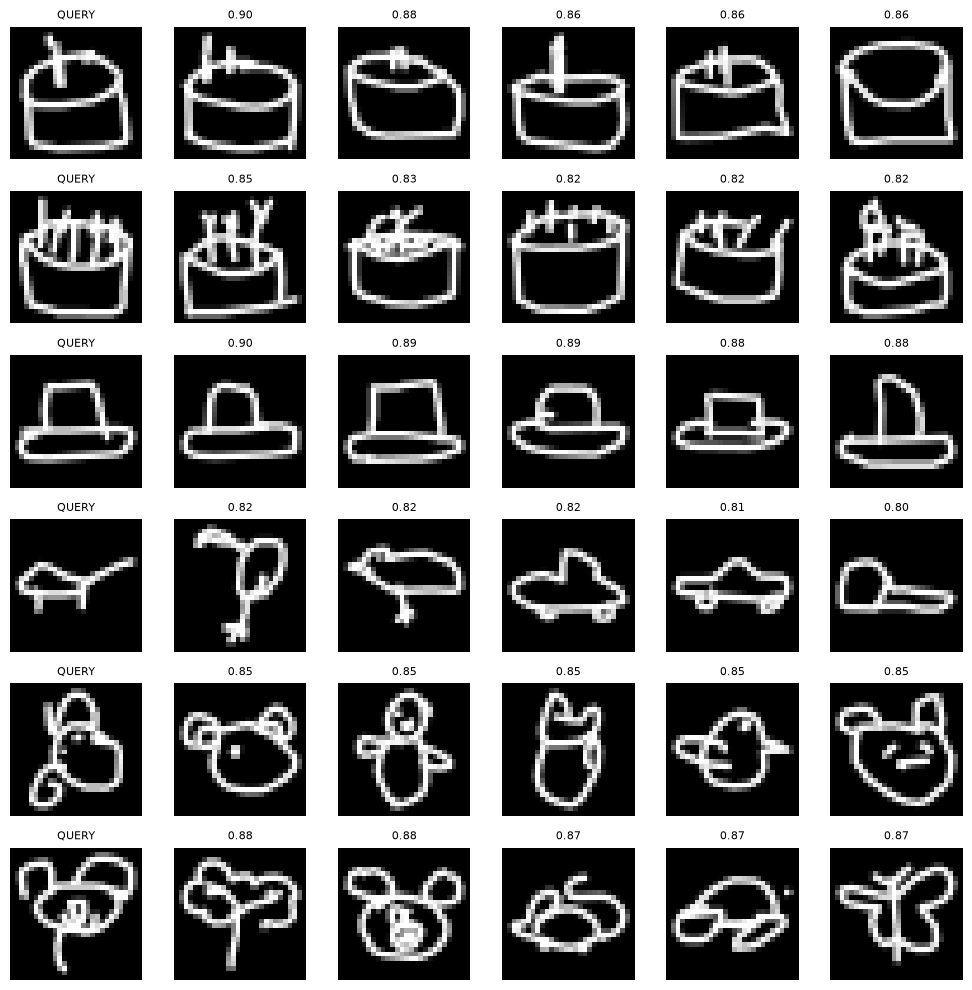

query was: mouse -> top 5: ['bird' 'bird' 'car' 'car' 'hat']
query was: mouse -> top 5: ['bear' 'bear' 'bear' 'bird' 'bear']
query was: bear -> top 5: ['tree' 'bear' 'mouse' 'car' 'butterfly']


In [20]:
sims  = query_emb @ gallery_emb.T
order = np.argsort(-sims, axis=1)
p5_each = (gallery_labels[order[:, :5]] == query_labels[:, None]).mean(axis=1)

rng2 = np.random.default_rng(1)
good = rng2.choice(np.where(p5_each == 1.0)[0], 3, replace=False)
bad  = rng2.choice(np.where(p5_each <= 0.2)[0], 3, replace=False)

fig, axes = plt.subplots(6, 6, figsize=(10, 10))
for r, q in enumerate(list(good) + list(bad)):
    axes[r, 0].imshow(query_images[q].reshape(28, 28), cmap="gray"); axes[r, 0].set_title("QUERY", fontsize=8)
    for c in range(5):
        j = order[q, c]
        axes[r, c+1].imshow(gallery_images[j].reshape(28, 28), cmap="gray")
        axes[r, c+1].set_title(f"{sims[q, j]:.2f}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

for q in bad:
    print("query was:", query_labels[q], "-> top 5:", gallery_labels[order[q, :5]])